Optimal Power Generation:
Generator 1: 168.71 MW
Generator 2: 81.29 MW
Generator 3: 50.00 MW
Total Power: 300.0 MW
Minimum Fuel Cost: 2867.19 $/hr


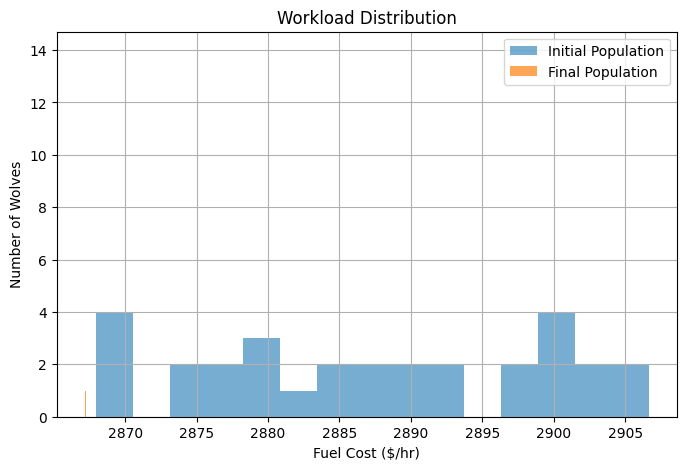

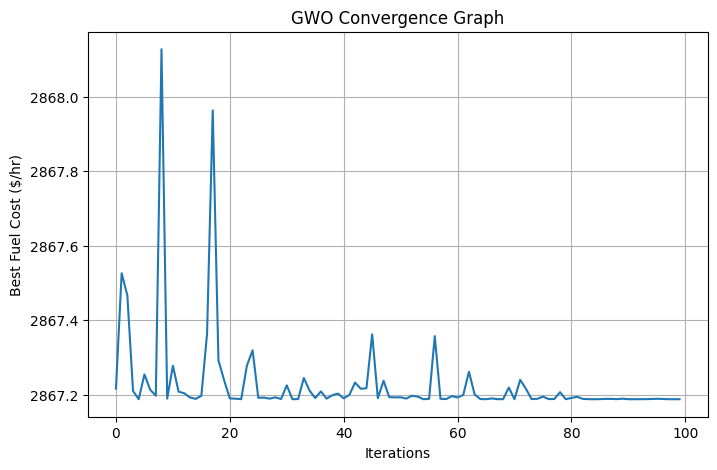

In [9]:
# Grey Wolf Optimization for Economic Load Dispatch

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 30
iterations = 100
demand = 300

pmin = np.array([100, 50, 50])
pmax = np.array([200, 150, 100])

a = np.array([0.003, 0.005, 0.007])
b = np.array([5.3, 5.5, 5.8])
c = np.array([500, 400, 200])

def repair(p):
    p = np.clip(p, pmin, pmax)
    diff = demand - np.sum(p)

    for i in range(3):
        change = np.clip(diff, pmin[i] - p[i], pmax[i] - p[i])
        p[i] += change
        diff -= change

    return p

def fitness(p):
    return np.sum(a * p**2 + b * p + c)

wolves = np.array([
    repair(np.random.uniform(pmin, pmax))
    for _ in range(n)
])

initial = [fitness(w) for w in wolves]
convergence = []

for t in range(iterations):
    scores = np.array([fitness(w) for w in wolves])
    idx = np.argsort(scores)

    alpha = wolves[idx[0]].copy()
    beta = wolves[idx[1]].copy()
    delta = wolves[idx[2]].copy()

    A_factor = 2 - 2 * t / iterations

    new_wolves = []

    for wolf in wolves:
        positions = []

        for leader in [alpha, beta, delta]:
            A = 2 * A_factor * np.random.rand(3) - A_factor
            C = 2 * np.random.rand(3)

            D = abs(C * leader - wolf)
            positions.append(leader - A * D)

        new_wolf = np.mean(positions, axis=0)
        new_wolf = repair(new_wolf)
        new_wolves.append(new_wolf)

    wolves = np.array(new_wolves)

    best = wolves[np.argmin([fitness(w) for w in wolves])]
    convergence.append(fitness(best))

best = wolves[np.argmin([fitness(w) for w in wolves])]

print("Optimal Power Generation:")
for i in range(3):
    print(f"Generator {i+1}: {best[i]:.2f} MW")

print("Total Power:", round(np.sum(best), 2), "MW")
print("Minimum Fuel Cost:", round(fitness(best), 2), "$/hr")

final = [fitness(w) for w in wolves]

plt.figure(figsize=(8, 5))
plt.hist(initial, bins=15, alpha=0.6, label="Initial Population")
plt.hist(final, bins=15, alpha=0.7, label="Final Population")
plt.xlabel("Fuel Cost ($/hr)")
plt.ylabel("Number of Wolves")
plt.title("Workload Distribution")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Best Fuel Cost ($/hr)")
plt.title("GWO Convergence Graph")
plt.grid()
plt.show()
